# Figure 4/5 - CV, SHAP and LOSO

This notebook builds the final ML figures from the article-aligned configurations.
Shared paths and reusable helpers are imported from `config.py` and `common.py`.

In [1]:
import logging
import os
import re
import warnings
from pathlib import Path

import joblib
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from xgboost import XGBClassifier

from config import (
    DEFAULT_METADATA_PATH,
    DEFAULT_PATH_PATH,
    DEFAULT_TAX_PATH,
    INNER_FOLDS,
    META_COLS,
    OUTER_FOLDS,
    OUTPUT_DIR as PROJECT_OUTPUT_DIR,
    PATHWAY_SCALE,
    RANDOM_STATE,
    UNWANTED_PATHWAY_COLS,
)
from common import (
    apply_clr,
    compute_metrics,
    numeric_feature_frame,
    prevalence_bioproject_filter,
    rank_std_fit,
    rank_std_transform,
    read_csv_with_run,
)

warnings.filterwarnings("ignore")
warnings.filterwarnings("ignore", category=UserWarning, message=".*sklearn.utils.parallel.*")
os.environ["PYTHONWARNINGS"] = "ignore::UserWarning,ignore::FutureWarning,ignore::DeprecationWarning"

for logger_name in ("shap", "sklearn", "xgboost", "numba", "matplotlib"):
    logging.getLogger(logger_name).setLevel(logging.ERROR)

try:
    import xgboost as _xgb
    _xgb.set_config(verbosity=0)
except Exception:
    pass

FIG4_OUTPUT_DIR = Path(os.getenv("SALIVARY_WGS_FIG4_OUTPUT_DIR", PROJECT_OUTPUT_DIR / "fig_4_5_ml"))
FIG_DIR = FIG4_OUTPUT_DIR / "figures"
MODEL_DIR = FIG4_OUTPUT_DIR / "models"

FIG4_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

FONT_SIZE = 14
SHAP_TOP_N = 45


In [2]:
CONFIGS = [
    {"task": "K05", "feature_set": "TAX",      "transform": "CLR",      "model": "LR_Ridge"},
    {"task": "K05", "feature_set": "TAX+PATH", "transform": "CLR",      "model": "LR_Ridge"},
    {"task": "K05", "feature_set": "PATH",     "transform": "CLR",      "model": "LR_Ridge"},
    {"task": "K02", "feature_set": "TAX",      "transform": "rank.std", "model": "XGBoost"},
    {"task": "K02", "feature_set": "TAX+PATH", "transform": "CLR",      "model": "RF"},
    {"task": "K02", "feature_set": "PATH",     "transform": "CLR",      "model": "RF"},
]

PARAM_GRIDS = {
    "LR_Ridge": {"C": [0.001, 0.01, 0.1, 1, 10, 100]},
    "XGBoost": {
        "n_estimators": [100, 300],
        "max_depth": [3, 5],
        "learning_rate": [0.01, 0.1],
        "subsample": [0.7, 1.0],
        "colsample_bytree": [0.7, 1.0],
    },
    "RF": {
        "n_estimators": [100, 300, 500],
        "max_depth": [None, 5, 10],
        "max_features": ["sqrt", 0.3],
    },
}

ROC_COLORS = {
    "TAX": "#4878D0",
    "TAX+PATH": "#EE854A",
    "PATH": "#6ACC65",
}

DIS_COLOR = {"K05": "#7F86C0", "K02": "#C4A86A"}
DIS_LABEL = {"K05": "Periodontitis (K05)", "K02": "Caries (K02)"}


## Shared ML helpers used by this figure

In [3]:
def get_task_masks(meta: pd.DataFrame, task: str) -> dict[str, np.ndarray]:
    if task == "K05":
        target = meta["K05_gingivitis_periodontitis"].to_numpy(dtype=bool)
    elif task == "K02":
        target = meta["K02_caries"].to_numpy(dtype=bool)
    else:
        raise ValueError(task)

    healthy_mask = meta["healthy"].to_numpy(dtype=bool)
    eligible = target | healthy_mask
    return {"target": target, "eligible": eligible}


def build_xy(
    cfg: dict,
    X_tax_all: np.ndarray,
    X_path_all: np.ndarray,
    mask_idx: np.ndarray,
    bp_all: np.ndarray,
    fit_filter: bool = True,
    keep_tax_ext: np.ndarray | None = None,
    keep_path_ext: np.ndarray | None = None,
) -> tuple[np.ndarray, int, np.ndarray, np.ndarray]:
    feature_set = cfg["feature_set"]
    bp = bp_all[mask_idx]

    if fit_filter:
        keep_tax = prevalence_bioproject_filter(X_tax_all[mask_idx], bp)
        keep_path = prevalence_bioproject_filter(X_path_all[mask_idx], bp)
    else:
        keep_tax = keep_tax_ext
        keep_path = keep_path_ext

    if keep_tax is None or keep_path is None:
        raise ValueError("Feature masks are not defined")

    X_tax = X_tax_all[mask_idx][:, keep_tax]
    X_path = X_path_all[mask_idx][:, keep_path]
    n_tax = X_tax.shape[1]

    if feature_set == "TAX":
        X_raw = X_tax
    elif feature_set == "PATH":
        X_raw = X_path
    elif feature_set == "TAX+PATH":
        X_raw = np.concatenate([X_tax, X_path], axis=1)
    else:
        raise ValueError(feature_set)

    return X_raw, n_tax, keep_tax, keep_path


def transform_fold(
    X_train: np.ndarray,
    X_test: np.ndarray,
    transform: str,
    feature_set: str,
    n_tax: int | None = None,
) -> tuple[np.ndarray, np.ndarray]:
    if transform == "CLR":
        if feature_set == "TAX+PATH":
            if n_tax is None:
                raise ValueError("n_tax is required for TAX+PATH CLR")
            X_train_tax = apply_clr(X_train[:, :n_tax])
            X_test_tax = apply_clr(X_test[:, :n_tax])
            X_train_path = apply_clr(X_train[:, n_tax:], force_relative=True)
            X_test_path = apply_clr(X_test[:, n_tax:], force_relative=True)
            return (
                np.concatenate([X_train_tax, X_train_path], axis=1),
                np.concatenate([X_test_tax, X_test_path], axis=1),
            )

        if feature_set == "PATH":
            return apply_clr(X_train, force_relative=True), apply_clr(X_test, force_relative=True)

        return apply_clr(X_train), apply_clr(X_test)

    if transform == "rank.std":
        mu, std = rank_std_fit(X_train)
        return rank_std_transform(X_train, mu, std), rank_std_transform(X_test, mu, std)

    raise ValueError(transform)


def get_model(name: str):
    if name == "LR_Ridge":
        return LogisticRegression(
            penalty="l2",
            solver="lbfgs",
            max_iter=1000,
            random_state=RANDOM_STATE,
        )
    if name == "XGBoost":
        return XGBClassifier(
            eval_metric="logloss",
            verbosity=0,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )
    if name == "RF":
        return RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)
    raise ValueError(name)


def tune_and_predict(
    X_train: np.ndarray,
    y_train: np.ndarray,
    X_test: np.ndarray,
    model_name: str,
) -> tuple[np.ndarray, object]:
    model = get_model(model_name)

    if len(np.unique(y_train)) < 2:
        return np.full(len(X_test), 0.5), model

    grid = PARAM_GRIDS.get(model_name, {})
    n_pos = int(y_train.sum())
    n_neg = int((y_train == 0).sum())

    if grid and n_pos >= INNER_FOLDS and n_neg >= INNER_FOLDS:
        grid_search = GridSearchCV(
            model,
            grid,
            cv=StratifiedKFold(n_splits=INNER_FOLDS, shuffle=True, random_state=RANDOM_STATE),
            scoring="roc_auc",
            refit=True,
            n_jobs=-1,
        )
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            grid_search.fit(X_train, y_train)
        best_model = grid_search.best_estimator_
        return best_model.predict_proba(X_test)[:, 1], best_model

    model.fit(X_train, y_train)
    return model.predict_proba(X_test)[:, 1], model


def auc_mcc(y_true: np.ndarray, probs: np.ndarray) -> tuple[float | None, float | None]:
    metrics = compute_metrics(y_true, probs)
    if metrics is None:
        return None, None
    return metrics["AUC"], metrics["MCC"]


## Figure helpers

In [4]:
def fmt_taxon_shap(raw: str) -> str:
    name = str(raw)
    if len(name) > 3 and name[1:3] == "__":
        name = name[3:]
    name = name.replace("_", " ").strip()

    parts = name.split()
    if len(parts) < 2:
        return name

    genus = parts[0]
    species = " ".join(parts[1:])

    is_code = bool(
        re.match(r"^(GGB|TM\d|[0-9])", genus)
        or (genus.isupper() and len(genus) <= 4)
    )
    if is_code:
        return name

    genus_real = genus[0].isupper() and genus[1:].islower() and len(genus) > 2
    species_anon = bool(re.match(r"^(SGB|GGB|[0-9])", parts[1]))

    if genus_real and not species_anon:
        return f"{genus[0]}. {species}"
    if genus_real and species_anon:
        return f"{genus} sp."
    return name


def fmt_pathway_shap(raw: str) -> str:
    name = str(raw)
    if len(name) > 3 and name[1:3] == "__":
        name = name[3:]
    if ": " in name:
        return name.split(": ")[0].strip()
    return name.split("..")[0].replace(".", "-")


def is_pathway_feature(name: str) -> bool:
    return (
        ": " in name
        or ".." in name
        or bool(re.match(r"^(PWY|ARGININE|GLYCO|POLY|P[0-9]|[A-Z0-9]{2,}-)", name))
    )


def fmt_feature_shap(name: str) -> str:
    return fmt_pathway_shap(name) if is_pathway_feature(name) else fmt_taxon_shap(name)


def apply_italic_taxa(ax) -> None:
    for label in ax.get_yticklabels():
        if not is_pathway_feature(label.get_text()):
            label.set_fontstyle("italic")
    ax.figure.canvas.draw_idle()


def save_fig(fig, name: str) -> None:
    base = FIG_DIR / name
    fig.savefig(f"{base}.svg", bbox_inches="tight", transparent=True)
    fig.savefig(f"{base}.png", dpi=300, bbox_inches="tight", transparent=True)
    print(f"  saved -> {base}.[svg|png]")


In [5]:
def plot_roc(task_results: list[dict], task: str, ax) -> None:
    fpr_grid = np.linspace(0, 1, 200)

    for result in task_results:
        color = ROC_COLORS.get(result["feature_set"], "#AAAAAA")
        label = (
            f"{result['feature_set']} | {result['transform']} | {result['model']}"
            f"  AUC={result['mean_auc']:.3f}+/-{result['std_auc']:.3f}"
        )

        tprs = []
        for fpr, tpr in result["fold_curves"]:
            interp_tpr = np.interp(fpr_grid, fpr, tpr)
            interp_tpr[0] = 0.0
            interp_tpr[-1] = 1.0
            tprs.append(interp_tpr)

        tprs = np.array(tprs)
        mean_tpr = tprs.mean(axis=0)
        sd_tpr = tprs.std(axis=0)

        ax.plot(fpr_grid, mean_tpr, lw=2.4, color=color, label=label)
        ax.fill_between(
            fpr_grid,
            np.clip(mean_tpr - sd_tpr, 0, 1),
            np.clip(mean_tpr + sd_tpr, 0, 1),
            color=color,
            alpha=0.14,
        )

    ax.plot([0, 1], [0, 1], "--", color="#BDB8AF", lw=1.4, alpha=0.9, label="Random  AUC = 0.500")
    ax.set_xlabel("False Positive Rate", fontsize=10)
    ax.set_ylabel("True Positive Rate", fontsize=10)
    ax.set_title(DIS_LABEL[task], color=DIS_COLOR[task], fontweight="bold", fontsize=12)
    ax.legend(loc="lower right", fontsize=7.5, framealpha=0.95)
    ax.set_xlim([0, 1])
    ax.set_ylim([0, 1.02])
    ax.set_facecolor("#FAFAF8")
    ax.grid(alpha=0.12, color="#CCCCCC")

    for spine in ax.spines.values():
        spine.set_edgecolor("#DDDDDD")


In [6]:
def run_shap_model(result: dict) -> tuple[shap.Explanation, object]:
    cfg = result["cfg"]
    task = cfg["task"]
    feature_set = cfg["feature_set"]
    transform = cfg["transform"]
    model_name = cfg["model"]

    masks = get_task_masks(df, task)
    y = masks["target"].astype(int)
    train_idx = np.where(masks["eligible"])[0]

    X_train, n_tax, keep_tax, keep_path = build_xy(
        cfg,
        X_tax_raw,
        X_path_raw,
        train_idx,
        bioproject,
    )
    y_train = y[train_idx]

    selected_tax_names = [tax_cols[i] for i, keep in enumerate(keep_tax) if keep]
    selected_path_names = [path_cols[i] for i, keep in enumerate(keep_path) if keep]

    if feature_set == "TAX":
        raw_names = selected_tax_names
    elif feature_set == "PATH":
        raw_names = selected_path_names
    else:
        raw_names = selected_tax_names + selected_path_names

    feature_names = [fmt_feature_shap(name) for name in raw_names]
    X_transformed, _ = transform_fold(X_train, X_train, transform, feature_set, n_tax)

    model = get_model(model_name)
    grid = PARAM_GRIDS.get(model_name, {})

    if grid:
        grid_search = GridSearchCV(
            model,
            grid,
            cv=StratifiedKFold(n_splits=INNER_FOLDS, shuffle=True, random_state=RANDOM_STATE),
            scoring="roc_auc",
            refit=True,
            n_jobs=-1,
        )
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            grid_search.fit(X_transformed, y_train)
        fitted = grid_search.best_estimator_
        print(f"  SHAP best params: {grid_search.best_params_}")
    else:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            model.fit(X_transformed, y_train)
        fitted = model

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        if model_name == "LR_Ridge":
            shap_values = shap.LinearExplainer(fitted, X_transformed).shap_values(X_transformed)
        else:
            raw_values = shap.TreeExplainer(fitted).shap_values(X_transformed)
            if isinstance(raw_values, list):
                shap_values = raw_values[1]
            else:
                shap_values = np.asarray(raw_values)
                if shap_values.ndim == 3:
                    shap_values = shap_values[:, :, 1]

    top_idx = np.argsort(np.abs(shap_values).mean(axis=0).ravel())[::-1][:SHAP_TOP_N]
    explanation = shap.Explanation(
        values=shap_values[:, top_idx],
        data=X_transformed[:, top_idx],
        feature_names=[feature_names[i] for i in top_idx],
    )
    return explanation, fitted


In [7]:
def run_loso(cfg: dict, bp_all: np.ndarray) -> dict[str, dict]:
    feature_set = cfg["feature_set"]
    transform = cfg["transform"]
    model_name = cfg["model"]
    task = cfg["task"]

    masks = get_task_masks(df, task)
    y = masks["target"].astype(int)
    eligible = masks["eligible"]

    results = {}
    for test_bp in sorted(np.unique(bp_all)):
        test_mask = bp_all == test_bp
        train_mask = (~test_mask) & eligible
        eval_mask = test_mask & eligible

        train_idx = np.where(train_mask)[0]
        test_idx = np.where(eval_mask)[0]

        if len(test_idx) < 3:
            continue

        y_test = y[test_idx]
        if len(np.unique(y_test)) < 2:
            continue

        X_train, n_tax, keep_tax, keep_path = build_xy(
            cfg,
            X_tax_raw,
            X_path_raw,
            train_idx,
            bp_all,
        )
        X_test, _, _, _ = build_xy(
            cfg,
            X_tax_raw,
            X_path_raw,
            test_idx,
            bp_all,
            fit_filter=False,
            keep_tax_ext=keep_tax,
            keep_path_ext=keep_path,
        )

        y_train = y[train_idx]
        X_train_t, X_test_t = transform_fold(X_train, X_test, transform, feature_set, n_tax)
        probs, _ = tune_and_predict(X_train_t, y_train, X_test_t, model_name)

        auc, mcc = auc_mcc(y_test, probs)
        if auc is None:
            continue

        n_pos = int(y_test.sum())
        n_neg = int((y_test == 0).sum())
        results[test_bp] = {
            "auc": round(float(auc), 4),
            "mcc": round(float(mcc or 0), 4),
            "n_pos": n_pos,
            "n_neg": n_neg,
        }
        print(f"  {test_bp:<20} AUC={auc:.4f}  MCC={mcc:.4f}  cases={n_pos}  healthy={n_neg}")

    return results


def plot_loso_heatmap(loso_by_cfg: dict[str, dict], ax_heat, task: str) -> None:
    cfg_labels = list(loso_by_cfg.keys())
    all_studies = sorted({study for values in loso_by_cfg.values() for study in values})

    auc_mat = np.full((len(all_studies), len(cfg_labels)), np.nan)
    mcc_mat = np.full((len(all_studies), len(cfg_labels)), np.nan)

    for col_idx, label in enumerate(cfg_labels):
        for row_idx, study in enumerate(all_studies):
            if study in loso_by_cfg[label]:
                auc_mat[row_idx, col_idx] = loso_by_cfg[label][study]["auc"]
                mcc_mat[row_idx, col_idx] = loso_by_cfg[label][study]["mcc"]

    n_obs = np.sum(~np.isnan(auc_mat), axis=0, keepdims=True)
    mean_auc = np.nanmean(auc_mat, axis=0, keepdims=True)
    se_auc = np.nanstd(auc_mat, axis=0, keepdims=True) / np.sqrt(n_obs)
    mean_mcc = np.nanmean(mcc_mat, axis=0, keepdims=True)
    se_mcc = np.nanstd(mcc_mat, axis=0, keepdims=True) / np.sqrt(n_obs)

    auc_plot = np.vstack([auc_mat, mean_auc])
    cmap = mcolors.LinearSegmentedColormap.from_list("rg", ["#D9534F", "#F5E642", "#5CB85C"])
    cmap.set_bad("#EEEEEE")
    norm = mcolors.Normalize(vmin=0.4, vmax=1.0)

    im = ax_heat.imshow(auc_plot, cmap=cmap, norm=norm, aspect="auto")

    row_labels = []
    for study in all_studies:
        for values in loso_by_cfg.values():
            if study in values:
                row = values[study]
                row_labels.append(
                    f"{study} (n={row['n_pos'] + row['n_neg']})\n"
                    f"{row['n_pos']} cases   {row['n_neg']} controls"
                )
                break
    row_labels.append("Mean +/- SE")

    ax_heat.set_yticks(range(len(row_labels)))
    ax_heat.set_yticklabels([""] * len(row_labels))
    ax_heat.tick_params(axis="y", length=0)
    ax_heat.set_xticks(range(len(cfg_labels)))
    ax_heat.set_xticklabels(cfg_labels, fontsize=FONT_SIZE, rotation=12, ha="right")

    label_fs = max(8, FONT_SIZE - 1)
    for row_idx, label in enumerate(row_labels):
        ax_heat.text(
            -0.02,
            row_idx,
            label,
            transform=ax_heat.get_yaxis_transform(),
            ha="right",
            va="center",
            fontsize=label_fs,
            linespacing=1.08,
            clip_on=False,
        )

    for row_idx in range(len(all_studies)):
        for col_idx in range(len(cfg_labels)):
            auc_value = auc_mat[row_idx, col_idx]
            mcc_value = mcc_mat[row_idx, col_idx]
            if not np.isnan(auc_value):
                ax_heat.text(
                    col_idx,
                    row_idx,
                    f"AUC={auc_value:.3f}\nMCC={mcc_value:.3f}",
                    ha="center",
                    va="center",
                    fontsize=FONT_SIZE,
                    linespacing=1.25,
                    color="#2A2A2A",
                )

    mean_row_idx = len(all_studies)
    for col_idx in range(len(cfg_labels)):
        auc_value = float(mean_auc[0, col_idx])
        mcc_value = float(mean_mcc[0, col_idx])
        if not np.isnan(auc_value):
            ax_heat.text(
                col_idx,
                mean_row_idx,
                f"AUC={auc_value:.3f}+/-{float(se_auc[0, col_idx]):.3f}\n"
                f"MCC={mcc_value:.3f}+/-{float(se_mcc[0, col_idx]):.3f}",
                ha="center",
                va="center",
                fontsize=FONT_SIZE,
                linespacing=1.25,
                fontweight="bold",
                color="#2A2A2A",
            )

    ax_heat.axhline(len(all_studies) - 0.5, color="#888888", lw=1.0)
    ax_heat.set_title(
        f"{DIS_LABEL[task]} - LOSO transferability",
        color=DIS_COLOR[task],
        fontweight="bold",
        fontsize=FONT_SIZE + 1,
    )
    cbar = plt.colorbar(im, ax=ax_heat, fraction=0.05, pad=0.02, label="AUC")
    cbar.ax.tick_params(labelsize=FONT_SIZE)


## Load and align data

In [8]:
print("Loading data...")

meta = read_csv_with_run(DEFAULT_METADATA_PATH)
tax = read_csv_with_run(DEFAULT_TAX_PATH)
path = read_csv_with_run(DEFAULT_PATH_PATH)

required_meta_cols = {"run", "bioproject", "healthy", "K02_caries", "K05_gingivitis_periodontitis"}
missing_meta_cols = sorted(required_meta_cols - set(meta.columns))
if missing_meta_cols:
    raise ValueError(f"Metadata is missing required columns: {missing_meta_cols}")

for col in ["healthy", "K02_caries", "K05_gingivitis_periodontitis"]:
    meta[col] = pd.to_numeric(meta[col], errors="coerce").fillna(0).astype(int)

meta["bioproject"] = meta["bioproject"].astype(str)

tax_cols = [col for col in tax.columns if col not in META_COLS]
path_cols = [
    col for col in path.columns
    if col not in META_COLS
    and col not in UNWANTED_PATHWAY_COLS
    and "|" not in col
]

common_runs = sorted(set(meta["run"]) & set(tax["run"]) & set(path["run"]))
if not common_runs:
    raise ValueError("No common runs across metadata, tax and path tables")

meta_aligned = (
    meta.loc[meta["run"].isin(common_runs)]
    .drop_duplicates("run")
    .sort_values("run")
    .set_index("run")
)
tax_aligned = (
    tax.loc[tax["run"].isin(common_runs), ["run"] + tax_cols]
    .drop_duplicates("run")
    .sort_values("run")
    .set_index("run")
)
path_aligned = (
    path.loc[path["run"].isin(common_runs), ["run"] + path_cols]
    .drop_duplicates("run")
    .sort_values("run")
    .set_index("run")
)

X_tax = numeric_feature_frame(tax_aligned, tax_cols)
X_path = numeric_feature_frame(path_aligned, path_cols) / PATHWAY_SCALE

df = meta_aligned.copy()
X_tax_raw = X_tax.to_numpy(dtype=float)
X_path_raw = X_path.to_numpy(dtype=float)
healthy = df["healthy"].to_numpy(dtype=bool)
bioproject = df["bioproject"].to_numpy(dtype=str)

print(f"Total samples : {len(df)}")
print(f"TAX cols      : {len(tax_cols)}    PATH cols: {len(path_cols)}")
print(f"Bioprojects   : {sorted(df['bioproject'].unique())}")
print()

for task in ["K05", "K02"]:
    masks = get_task_masks(df, task)
    n_pos = int(masks["target"].sum())
    n_neg = int(healthy.sum())
    n_eligible = int(masks["eligible"].sum())
    print(f"{task}: cases={n_pos}  controls={n_neg}  eligible={n_eligible}")


Loading data...
Total samples : 514
TAX cols      : 719    PATH cols: 522
Bioprojects   : ['PRJEB36291', 'PRJEB42701', 'PRJNA1057503', 'PRJNA1162519', 'PRJNA1379526', 'PRJNA380711', 'PRJNA396840', 'PRJNA478018', 'PRJNA678453', 'PRJNA717815', 'PRJNA741688', 'PRJNA752888', 'PRJNA929548', 'PRJNA932553']

K05: cases=161  controls=204  eligible=365
K02: cases=180  controls=204  eligible=384


## Cross-validation over final configurations

In [9]:
all_results = []

for cfg in CONFIGS:
    task = cfg["task"]
    feature_set = cfg["feature_set"]
    transform = cfg["transform"]
    model_name = cfg["model"]
    cfg_name = f"{task} | {feature_set} | {transform} | {model_name}"

    print(f"\n{'-' * 65}\n{cfg_name}")

    masks = get_task_masks(df, task)
    y = masks["target"].astype(int)
    eligible = masks["eligible"]
    eligible_idx = np.where(eligible)[0]
    strat_labels = np.array([f"{bioproject[i]}_{y[i]}" for i in eligible_idx])

    fold_aucs = []
    fold_mccs = []
    fold_curves = []
    oof_probs = np.full(len(y), np.nan)
    estimators = []

    outer_cv = StratifiedKFold(n_splits=OUTER_FOLDS, shuffle=True, random_state=RANDOM_STATE)

    for fold_idx, (train_pos, test_pos) in enumerate(outer_cv.split(X_tax_raw[eligible_idx], strat_labels), start=1):
        train_idx = eligible_idx[train_pos]
        test_idx = eligible_idx[test_pos]

        X_train, n_tax, keep_tax, keep_path = build_xy(
            cfg,
            X_tax_raw,
            X_path_raw,
            train_idx,
            bioproject,
        )
        X_test, _, _, _ = build_xy(
            cfg,
            X_tax_raw,
            X_path_raw,
            test_idx,
            bioproject,
            fit_filter=False,
            keep_tax_ext=keep_tax,
            keep_path_ext=keep_path,
        )

        y_train = y[train_idx]
        y_test = y[test_idx]

        X_train_t, X_test_t = transform_fold(X_train, X_test, transform, feature_set, n_tax)
        probs, estimator = tune_and_predict(X_train_t, y_train, X_test_t, model_name)

        estimators.append(estimator)
        oof_probs[test_idx] = probs

        auc, mcc = auc_mcc(y_test, probs)
        if auc is not None:
            fold_aucs.append(auc)
            fold_mccs.append(mcc)
            fpr, tpr, _ = roc_curve(y_test, probs)
            fold_curves.append((fpr, tpr))

        auc_text = f"{auc:.4f}" if auc is not None else "NA"
        mcc_text = f"{mcc:.4f}" if mcc is not None else "NA"
        print(
            f"  fold {fold_idx}  AUC={auc_text}  MCC={mcc_text}"
            f"  cases={int(y_test.sum())}  controls={int((y_test == 0).sum())}"
            f"  features={X_train.shape[1]}"
        )

    valid_mask = ~np.isnan(oof_probs)
    if valid_mask.sum() > 0 and len(np.unique(y[valid_mask])) > 1:
        oof_auc = roc_auc_score(y[valid_mask], oof_probs[valid_mask])
    else:
        oof_auc = np.nan

    mean_auc = float(np.mean(fold_aucs)) if fold_aucs else np.nan
    std_auc = float(np.std(fold_aucs)) if fold_aucs else np.nan
    mean_mcc = float(np.mean(fold_mccs)) if fold_mccs else np.nan

    print(f"  -> OOF AUC={oof_auc:.4f}  mean AUC={mean_auc:.4f}+/-{std_auc:.4f}  mean MCC={mean_mcc:.4f}")

    all_results.append({
        "task": task,
        "cfg_name": cfg_name,
        "feature_set": feature_set,
        "transform": transform,
        "model": model_name,
        "oof_auc": round(float(oof_auc), 4),
        "mean_auc": round(mean_auc, 4),
        "std_auc": round(std_auc, 4),
        "mean_mcc": round(mean_mcc, 4),
        "fold_curves": fold_curves,
        "y": y,
        "oof_probs": oof_probs,
        "estimators": estimators,
        "cfg": cfg,
    })



-----------------------------------------------------------------
K05 | TAX | CLR | LR_Ridge
  fold 1  AUC=0.9121  MCC=0.6398  cases=33  controls=40  features=344
  fold 2  AUC=0.9152  MCC=0.6875  cases=33  controls=40  features=339
  fold 3  AUC=0.8659  MCC=0.5804  cases=32  controls=41  features=350
  fold 4  AUC=0.9155  MCC=0.6178  cases=31  controls=42  features=344
  fold 5  AUC=0.8643  MCC=0.5527  cases=32  controls=41  features=345
  -> OOF AUC=0.8890  mean AUC=0.8946+/-0.0241  mean MCC=0.6156

-----------------------------------------------------------------
K05 | TAX+PATH | CLR | LR_Ridge
  fold 1  AUC=0.9174  MCC=0.6118  cases=33  controls=40  features=676
  fold 2  AUC=0.9144  MCC=0.6533  cases=33  controls=40  features=671
  fold 3  AUC=0.8605  MCC=0.5522  cases=32  controls=41  features=683
  fold 4  AUC=0.9117  MCC=0.6492  cases=31  controls=42  features=676
  fold 5  AUC=0.8811  MCC=0.6090  cases=32  controls=41  features=676
  -> OOF AUC=0.8944  mean AUC=0.8970+/-0.022

/home/jupyter-seraph/.conda/envs/pyEDA_env/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/jupyter-seraph/.conda/envs/pyEDA_env/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/jupyter-seraph/.conda/envs/pyEDA_env/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/jupyter

  fold 1  AUC=0.8411  MCC=0.5605  cases=36  controls=41  features=681


/home/jupyter-seraph/.conda/envs/pyEDA_env/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/jupyter-seraph/.conda/envs/pyEDA_env/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/jupyter-seraph/.conda/envs/pyEDA_env/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/jupyter

  fold 2  AUC=0.7415  MCC=0.4488  cases=35  controls=42  features=683


/home/jupyter-seraph/.conda/envs/pyEDA_env/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/jupyter-seraph/.conda/envs/pyEDA_env/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/jupyter-seraph/.conda/envs/pyEDA_env/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/jupyter

... (11 outputs left out)

/home/jupyter-seraph/.conda/envs/pyEDA_env/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/jupyter-seraph/.conda/envs/pyEDA_env/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/jupyter-seraph/.conda/envs/pyEDA_env/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/jupyter

  fold 4  AUC=0.6810  MCC=0.3714  cases=35  controls=42  features=332


/home/jupyter-seraph/.conda/envs/pyEDA_env/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/jupyter-seraph/.conda/envs/pyEDA_env/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/jupyter-seraph/.conda/envs/pyEDA_env/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/jupyter

  fold 5  AUC=0.7652  MCC=0.5575  cases=38  controls=38  features=333
  -> OOF AUC=0.7213  mean AUC=0.7183+/-0.0408  mean MCC=0.3896


In [10]:
summary = pd.DataFrame([
    {
        "config": result["cfg_name"],
        "oof_auc": result["oof_auc"],
        "mean_auc": result["mean_auc"],
        "std_auc": result["std_auc"],
        "mean_mcc": result["mean_mcc"],
    }
    for result in all_results
])

print(summary.to_string(index=False))
summary.to_csv(FIG4_OUTPUT_DIR / "cv_summary.csv", index=False)

best = {}
for task in ["K05", "K02"]:
    task_results = [result for result in all_results if result["task"] == task]
    best[task] = max(task_results, key=lambda result: result["mean_mcc"])
    print(
        f"\nBest {task}: {best[task]['cfg_name']}"
        f"  MCC={best[task]['mean_mcc']}  AUC={best[task]['mean_auc']}"
    )


                         config  oof_auc  mean_auc  std_auc  mean_mcc
     K05 | TAX | CLR | LR_Ridge   0.8890    0.8946   0.0241    0.6156
K05 | TAX+PATH | CLR | LR_Ridge   0.8944    0.8970   0.0224    0.6151
    K05 | PATH | CLR | LR_Ridge   0.8193    0.8231   0.0184    0.5158
 K02 | TAX | rank.std | XGBoost   0.8020    0.8091   0.0521    0.4693
      K02 | TAX+PATH | CLR | RF   0.7796    0.7821   0.0430    0.4808
          K02 | PATH | CLR | RF   0.7213    0.7183   0.0408    0.3896

Best K05: K05 | TAX | CLR | LR_Ridge  MCC=0.6156  AUC=0.8946

Best K02: K02 | TAX+PATH | CLR | RF  MCC=0.4808  AUC=0.7821


## K05 figures

  saved -> results_article_configs/fig_4_5_ml/figures/roc_cv_K05.[svg|png]


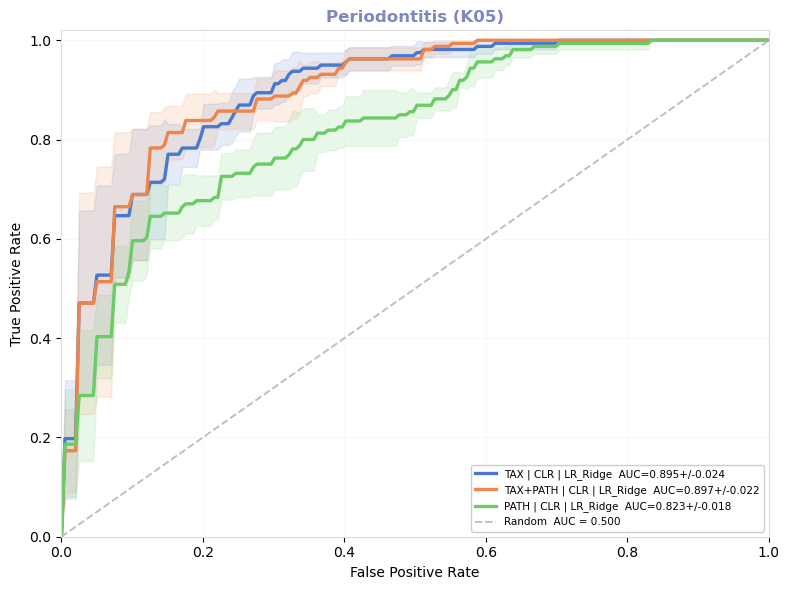

In [11]:
task = "K05"
task_results_k05 = [result for result in all_results if result["task"] == task]

fig, ax = plt.subplots(figsize=(8, 6), facecolor="none")
plot_roc(task_results_k05, task, ax)
ax.set_facecolor("none")
plt.tight_layout()
save_fig(fig, f"roc_cv_{task}")
plt.show()


SHAP for: K05 | TAX | CLR | LR_Ridge
  SHAP best params: {'C': 0.001}
  saved -> results_article_configs/fig_4_5_ml/figures/shap_K05.[svg|png]


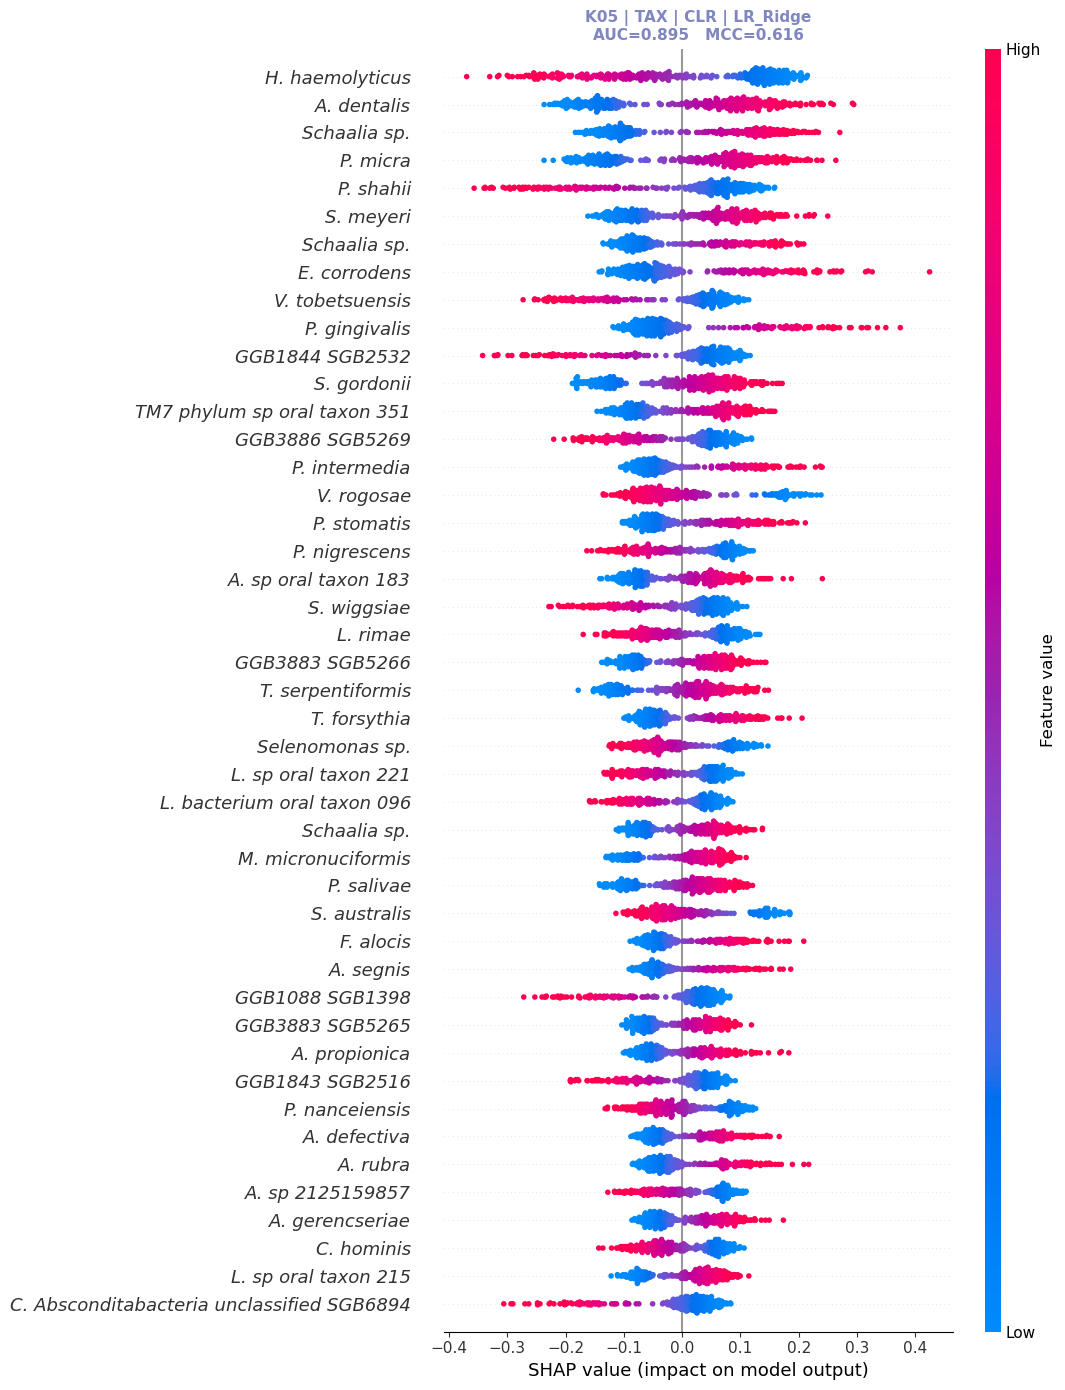

In [12]:
task = "K05"
b_k05 = best[task]
print(f"SHAP for: {b_k05['cfg_name']}")
shap_exp_k05, _ = run_shap_model(b_k05)

fig, ax = plt.subplots(figsize=(11, 14), facecolor="none")
shap.plots.beeswarm(shap_exp_k05, max_display=SHAP_TOP_N, show=False, plot_size=None, ax=ax)
apply_italic_taxa(ax)
ax.set_facecolor("none")
ax.set_title(
    f"{b_k05['cfg_name']}\nAUC={b_k05['mean_auc']:.3f}   MCC={b_k05['mean_mcc']:.3f}",
    color=DIS_COLOR["K05"],
    fontweight="bold",
    fontsize=11,
)
plt.tight_layout()
save_fig(fig, "shap_K05")
plt.show()



LOSO - K05 | TAX | CLR | LR_Ridge
  PRJNA1057503         AUC=0.7405  MCC=0.2893  cases=87  healthy=64
  PRJNA396840          AUC=0.9400  MCC=0.7035  cases=10  healthy=10
  PRJNA678453          AUC=0.8760  MCC=0.6472  cases=11  healthy=11
  PRJNA717815          AUC=0.9583  MCC=0.5620  cases=14  healthy=12
  PRJNA741688          AUC=0.7361  MCC=0.1612  cases=12  healthy=6
  PRJNA932553          AUC=0.8889  MCC=0.5922  cases=9  healthy=11

LOSO - K05 | TAX+PATH | CLR | LR_Ridge
  PRJNA1057503         AUC=0.7346  MCC=0.2698  cases=87  healthy=64
  PRJNA396840          AUC=1.0000  MCC=0.6547  cases=10  healthy=10
  PRJNA678453          AUC=0.8760  MCC=0.6472  cases=11  healthy=11
  PRJNA717815          AUC=0.9345  MCC=0.5620  cases=14  healthy=12
  PRJNA741688          AUC=0.7778  MCC=0.3508  cases=12  healthy=6
  PRJNA932553          AUC=0.8889  MCC=0.5922  cases=9  healthy=11

LOSO - K05 | PATH | CLR | LR_Ridge
  PRJNA1057503         AUC=0.6525  MCC=0.1932  cases=87  healthy=64
  PRJNA39

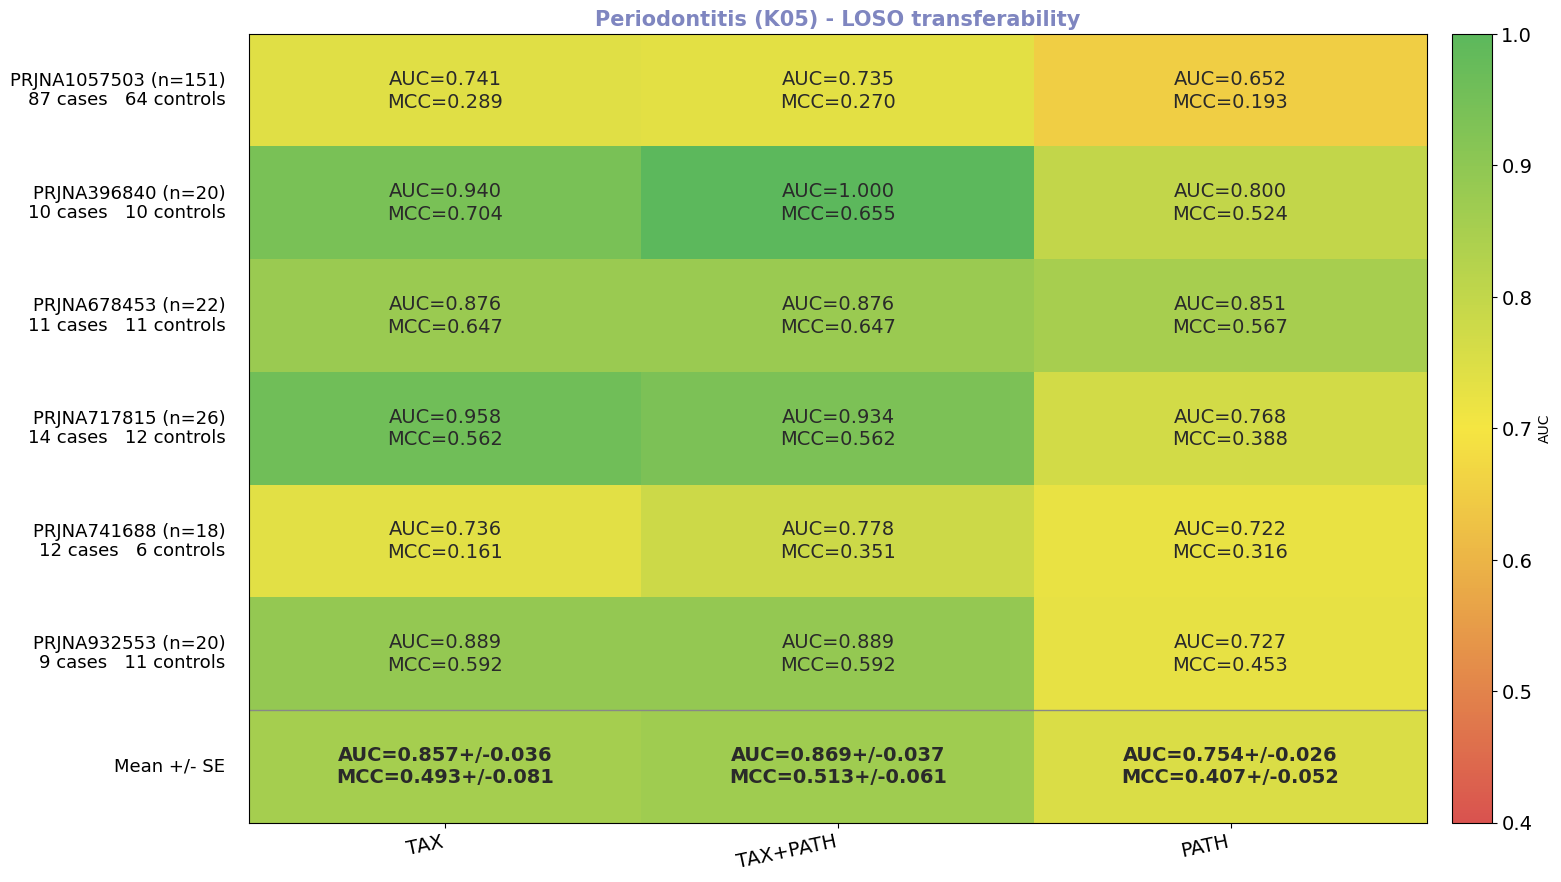

Mean AUC per config:
  TAX          0.8566
  TAX+PATH     0.8686
  PATH         0.7535


In [13]:
top3_k05 = sorted(task_results_k05, key=lambda result: result["mean_mcc"], reverse=True)[:3]

loso_k05 = {}
for result in top3_k05:
    print(f"\nLOSO - {result['cfg_name']}")
    loso_k05[result["feature_set"]] = run_loso(result["cfg"], bioproject)

n_studies = max(len(values) for values in loso_k05.values())
fig_h = max(6.8, n_studies * 1.35 + 1.4)
fig_w = 4.3 * len(loso_k05) + 6.0

fig, ax_heat = plt.subplots(1, 1, figsize=(fig_w, fig_h), facecolor="none")
ax_heat.set_facecolor("none")
plot_loso_heatmap(loso_k05, ax_heat, "K05")
fig.subplots_adjust(left=0.26, right=0.93, top=0.97, bottom=0.14)
save_fig(fig, "loso_K05")
plt.show()

loso_rows = [
    {"config": label, "bioproject": bp, **values}
    for label, loso in loso_k05.items()
    for bp, values in loso.items()
]
pd.DataFrame(loso_rows).to_csv(FIG4_OUTPUT_DIR / "loso_K05.csv", index=False)

print("Mean AUC per config:")
for label, loso in loso_k05.items():
    aucs = [values["auc"] for values in loso.values()]
    print(f"  {label:<12} {np.mean(aucs):.4f}")


## K02 figures

  saved -> results_article_configs/fig_4_5_ml/figures/roc_cv_K02.[svg|png]


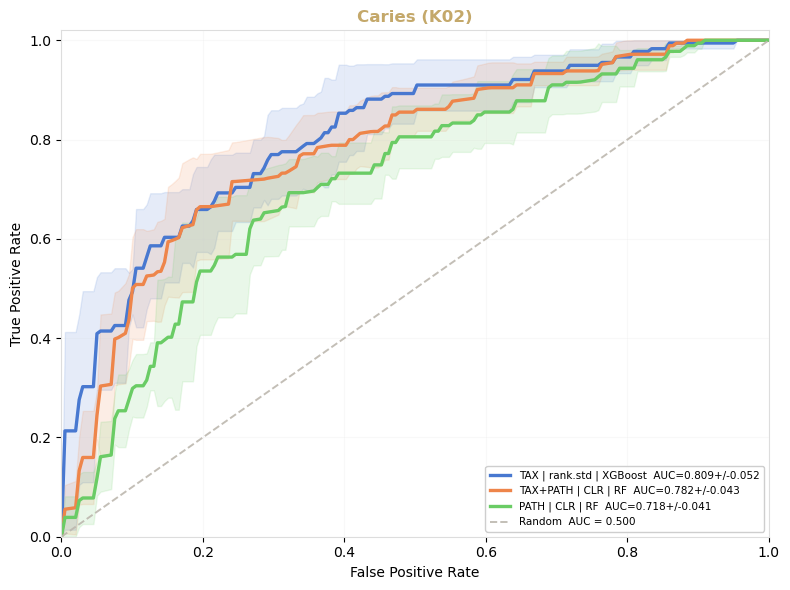

In [14]:
task = "K02"
task_results_k02 = [result for result in all_results if result["task"] == task]

fig, ax = plt.subplots(figsize=(8, 6), facecolor="none")
plot_roc(task_results_k02, task, ax)
ax.set_facecolor("none")
plt.tight_layout()
save_fig(fig, f"roc_cv_{task}")
plt.show()


SHAP for: K02 | TAX+PATH | CLR | RF


/home/jupyter-seraph/.conda/envs/pyEDA_env/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/jupyter-seraph/.conda/envs/pyEDA_env/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/jupyter-seraph/.conda/envs/pyEDA_env/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/jupyter

  SHAP best params: {'max_depth': 10, 'max_features': 0.3, 'n_estimators': 500}
  saved -> results_article_configs/fig_4_5_ml/figures/shap_K02.[svg|png]


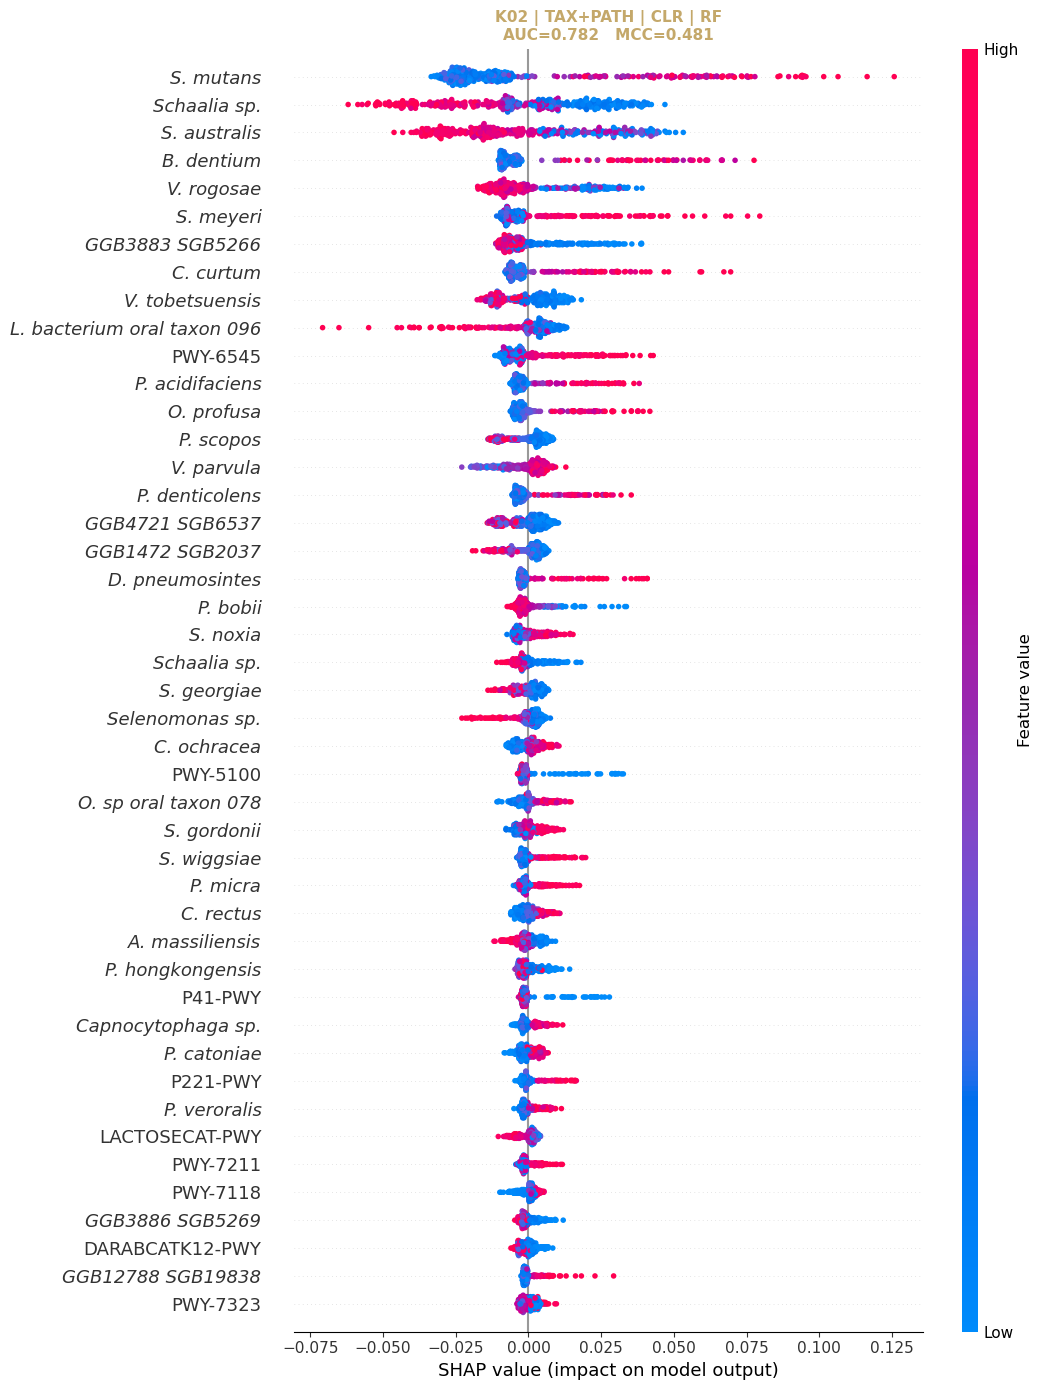

In [15]:
task = "K02"
b_k02 = best[task]
print(f"SHAP for: {b_k02['cfg_name']}")
shap_exp_k02, _ = run_shap_model(b_k02)

fig, ax = plt.subplots(figsize=(11, 14), facecolor="none")
shap.plots.beeswarm(shap_exp_k02, max_display=SHAP_TOP_N, show=False, plot_size=None, ax=ax)
apply_italic_taxa(ax)
ax.set_facecolor("none")
ax.set_title(
    f"{b_k02['cfg_name']}\nAUC={b_k02['mean_auc']:.3f}   MCC={b_k02['mean_mcc']:.3f}",
    color=DIS_COLOR["K02"],
    fontweight="bold",
    fontsize=11,
)
plt.tight_layout()
save_fig(fig, "shap_K02")
plt.show()



LOSO - K02 | TAX+PATH | CLR | RF


/home/jupyter-seraph/.conda/envs/pyEDA_env/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/jupyter-seraph/.conda/envs/pyEDA_env/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/jupyter-seraph/.conda/envs/pyEDA_env/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/jupyter

  PRJNA1057503         AUC=0.6413  MCC=0.1920  cases=73  healthy=64


/home/jupyter-seraph/.conda/envs/pyEDA_env/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/jupyter-seraph/.conda/envs/pyEDA_env/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/jupyter-seraph/.conda/envs/pyEDA_env/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/jupyter

  PRJNA380711          AUC=0.6663  MCC=0.3100  cases=25  healthy=19


/home/jupyter-seraph/.conda/envs/pyEDA_env/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/jupyter-seraph/.conda/envs/pyEDA_env/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/jupyter-seraph/.conda/envs/pyEDA_env/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/jupyter

... (13 outputs left out)

/home/jupyter-seraph/.conda/envs/pyEDA_env/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/jupyter-seraph/.conda/envs/pyEDA_env/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/jupyter-seraph/.conda/envs/pyEDA_env/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/jupyter

  PRJNA752888          AUC=0.5067  MCC=0.2075  cases=15  healthy=15


/home/jupyter-seraph/.conda/envs/pyEDA_env/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/jupyter-seraph/.conda/envs/pyEDA_env/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/jupyter-seraph/.conda/envs/pyEDA_env/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/jupyter

  PRJNA929548          AUC=0.8269  MCC=0.3555  cases=24  healthy=13
  saved -> results_article_configs/fig_4_5_ml/figures/loso_K02.[svg|png]


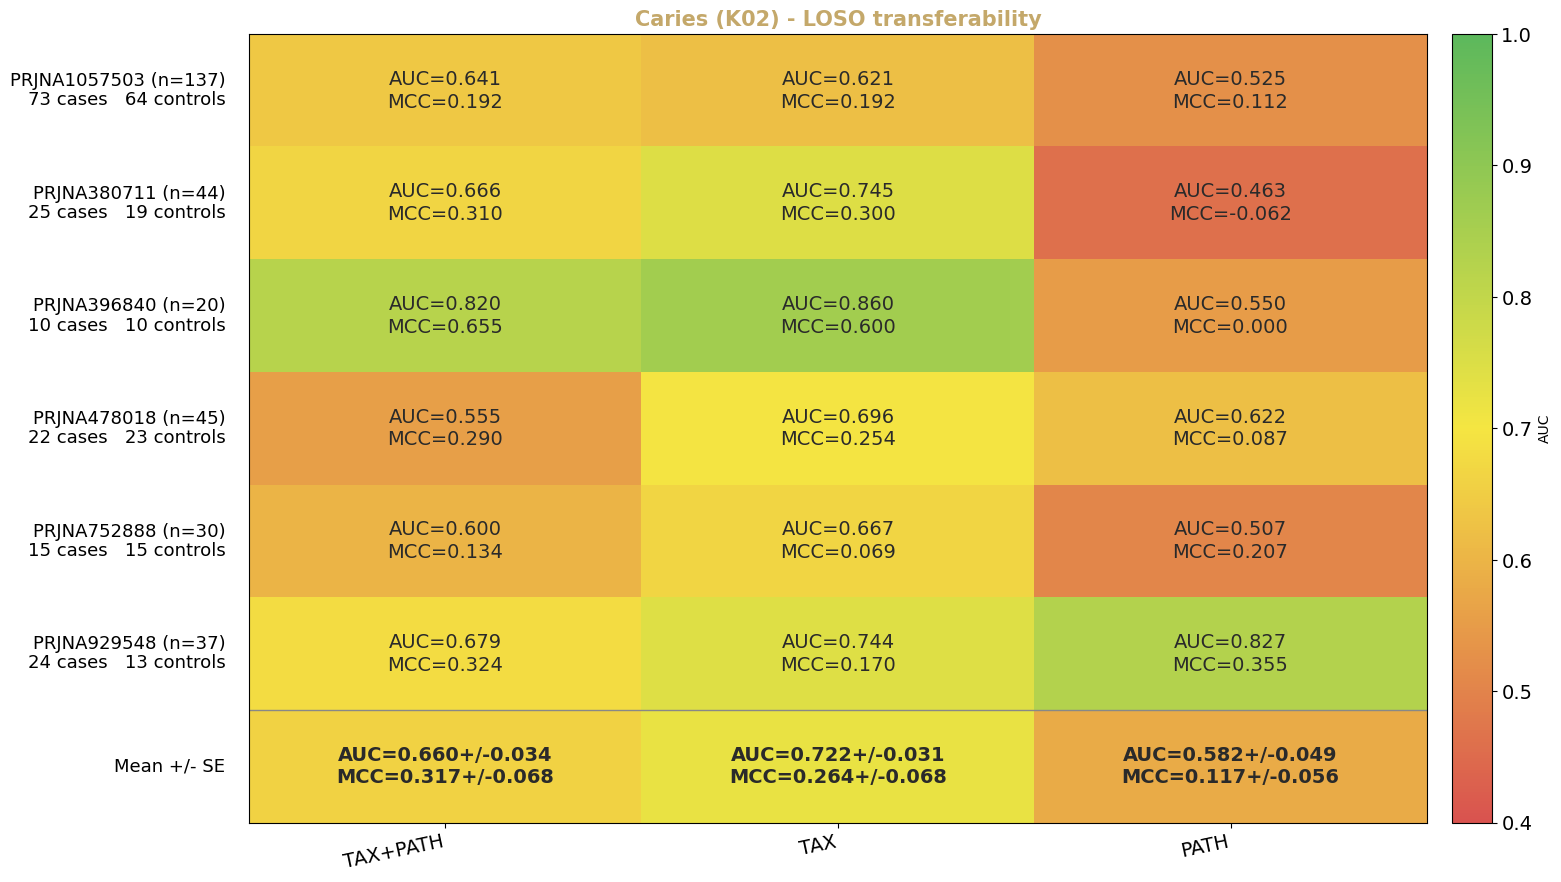

Mean AUC per config:
  TAX+PATH     0.6604
  TAX          0.7220
  PATH         0.5822


In [16]:
top3_k02 = sorted(task_results_k02, key=lambda result: result["mean_mcc"], reverse=True)[:3]

loso_k02 = {}
for result in top3_k02:
    print(f"\nLOSO - {result['cfg_name']}")
    loso_k02[result["feature_set"]] = run_loso(result["cfg"], bioproject)

n_studies = max(len(values) for values in loso_k02.values())
fig_h = max(6.8, n_studies * 1.35 + 1.4)
fig_w = 4.3 * len(loso_k02) + 6.0

fig, ax_heat = plt.subplots(1, 1, figsize=(fig_w, fig_h), facecolor="none")
ax_heat.set_facecolor("none")
plot_loso_heatmap(loso_k02, ax_heat, "K02")
fig.subplots_adjust(left=0.26, right=0.93, top=0.97, bottom=0.14)
save_fig(fig, "loso_K02")
plt.show()

loso_rows = [
    {"config": label, "bioproject": bp, **values}
    for label, loso in loso_k02.items()
    for bp, values in loso.items()
]
pd.DataFrame(loso_rows).to_csv(FIG4_OUTPUT_DIR / "loso_K02.csv", index=False)

print("Mean AUC per config:")
for label, loso in loso_k02.items():
    aucs = [values["auc"] for values in loso.values()]
    print(f"  {label:<12} {np.mean(aucs):.4f}")


## Save final TAX-only models

In [17]:
print("\nSaving best TAX-only models for Genotek inference")

for task in ["K05", "K02"]:
    tax_results = [
        result for result in all_results
        if result["task"] == task and result["feature_set"] == "TAX"
    ]
    if not tax_results:
        print(f"{task}: no TAX config - skipping")
        continue

    best_tax = max(tax_results, key=lambda result: result["mean_mcc"])
    cfg = best_tax["cfg"]
    feature_set = cfg["feature_set"]
    transform = cfg["transform"]
    model_name = cfg["model"]

    print(f"\n{task}: {best_tax['cfg_name']}  AUC={best_tax['mean_auc']}  MCC={best_tax['mean_mcc']}")

    masks = get_task_masks(df, task)
    y = masks["target"].astype(int)
    train_idx = np.where(masks["eligible"])[0]

    X_train, n_tax, keep_tax, keep_path = build_xy(
        cfg,
        X_tax_raw,
        X_path_raw,
        train_idx,
        bioproject,
    )
    y_train = y[train_idx]
    X_transformed, _ = transform_fold(X_train, X_train, transform, feature_set, n_tax)

    model = get_model(model_name)
    grid = PARAM_GRIDS.get(model_name, {})

    if grid:
        grid_search = GridSearchCV(
            model,
            grid,
            cv=StratifiedKFold(n_splits=INNER_FOLDS, shuffle=True, random_state=RANDOM_STATE),
            scoring="roc_auc",
            refit=True,
            n_jobs=-1,
        )
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            grid_search.fit(X_transformed, y_train)
        fitted = grid_search.best_estimator_
        print(f"  best params: {grid_search.best_params_}")
    else:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            model.fit(X_transformed, y_train)
        fitted = model

    transform_params = {}
    if transform == "rank.std":
        mu, std = rank_std_fit(X_train)
        transform_params = {"mu": mu, "std": std}

    bundle = {
        "task": task,
        "cfg_name": best_tax["cfg_name"],
        "model": fitted,
        "keep_tax": keep_tax,
        "keep_path": keep_path,
        "transform": transform,
        "transform_params": transform_params,
        "feature_set": feature_set,
        "n_tax": n_tax,
        "tax_cols": tax_cols,
        "path_cols": path_cols,
        "mean_auc": best_tax["mean_auc"],
        "mean_mcc": best_tax["mean_mcc"],
    }

    model_path = MODEL_DIR / f"best_model_{task}.joblib"
    joblib.dump(bundle, model_path)
    print(f"  saved -> {model_path}")

print("\nTo load and predict on Genotek data:")
print('  bundle = joblib.load("models/best_model_K05.joblib")')
print("  # align columns -> apply keep_tax mask -> transform -> model.predict_proba()")



Saving best TAX-only models for Genotek inference

K05: K05 | TAX | CLR | LR_Ridge  AUC=0.8946  MCC=0.6156
  best params: {'C': 0.001}
  saved -> results_article_configs/fig_4_5_ml/models/best_model_K05.joblib

K02: K02 | TAX | rank.std | XGBoost  AUC=0.8091  MCC=0.4693
  best params: {'colsample_bytree': 0.7, 'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 300, 'subsample': 0.7}
  saved -> results_article_configs/fig_4_5_ml/models/best_model_K02.joblib

To load and predict on Genotek data:
  bundle = joblib.load("models/best_model_K05.joblib")
  # align columns -> apply keep_tax mask -> transform -> model.predict_proba()
